#### Requirements

In [11]:
import pandas as pd
import numpy as np

import sys
sys.path.append("../..")

from src.backtester import calculate_return, backtester
from src.strategies import run_momentum_strategy, generate_momentum_signal
from src.summary import summary

In [12]:
df = pd.read_csv("../../data/spy_daily.csv")
prices = df["Adj Close"]
returns = calculate_return(prices)
lookback = 252

In [13]:
momentum_df, momentum_results = run_momentum_strategy(prices, returns, lookback, 0.001)
momentum_signal = generate_momentum_signal(prices, lookback)
momentum_position = momentum_df["position"]

#### Optimised Run Length Permutation Strategy

In [14]:
run_boundaries = []

run_boundaries.append(lookback + 1)

for i in range(lookback + 2, len(momentum_position)):
    if momentum_position.iloc[i] != momentum_position.iloc[i - 1]:
        run_boundaries.append(i)

run_boundaries.append(len(momentum_position))

In [15]:
run_lengths = []

for i in range(1, len(run_boundaries)):
    difference = float(run_boundaries[i]) - float(run_boundaries[i - 1])

    run_lengths.append(difference)

In [16]:
cash_runs = run_lengths[::2]
invested_runs = run_lengths[1::2]

In [17]:
def generate_random_signal_v5(cash_runs, invested_runs, lookback):

    random_cash_sequence = np.random.permutation(cash_runs).astype(int)
    random_invested_sequence = np.random.permutation(invested_runs).astype(int)

    sequence = []
        
    for i in range(len(cash_runs)):
        
        sequence.extend([0] * random_cash_sequence[i])
        sequence.extend([1] * random_invested_sequence[i])
    
    sequence.append(np.nan)
    
    random_signal = ([np.nan] * lookback) + sequence

    return random_signal

In [18]:
def run_simulation_v5(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal_v5(cash_runs, invested_runs, lookback)
        _, random_result = backtester(returns, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result

In [19]:
np.random.seed(44)

simulation_output = run_simulation_v5(1000)
simulation_df = pd.DataFrame(simulation_output)
simulation_df

,total_return,cagr,annual_volatility,annual_sharpe,max_drawdown,calmar,time_invested,trades
0,10.880236,0.101357,0.137969,0.768838,-0.313847,0.322950,0.775232,89
1,5.539611,0.076005,0.161014,0.535479,-0.367422,0.206859,0.775232,89
2,4.644221,0.069842,0.174890,0.473505,-0.536205,0.130252,0.775232,89
3,3.623271,0.061547,0.163593,0.446895,-0.551895,0.111519,0.775232,89
4,3.431431,0.059793,0.172358,0.423175,-0.551895,0.108342,0.775232,89
...,...,...,...,...,...,...,...,...
995,5.074617,0.072913,0.173595,0.492323,-0.571790,0.127517,0.775232,89
996,3.616051,0.061482,0.153879,0.464847,-0.394606,0.155807,0.775232,89
997,4.298148,0.067204,0.150994,0.506506,-0.420287,0.159901,0.775232,89
998,3.220776,0.057782,0.169755,0.415882,-0.608537,0.094952,0.775232,89


Sharpe Average: 0.4695
Sharpe Median:  0.4553
Largest Sharpe: 0.8610
Average No. of Trades: 89.0000
Average Time Invested: 0.7752
Empirical p-value: 0.0729


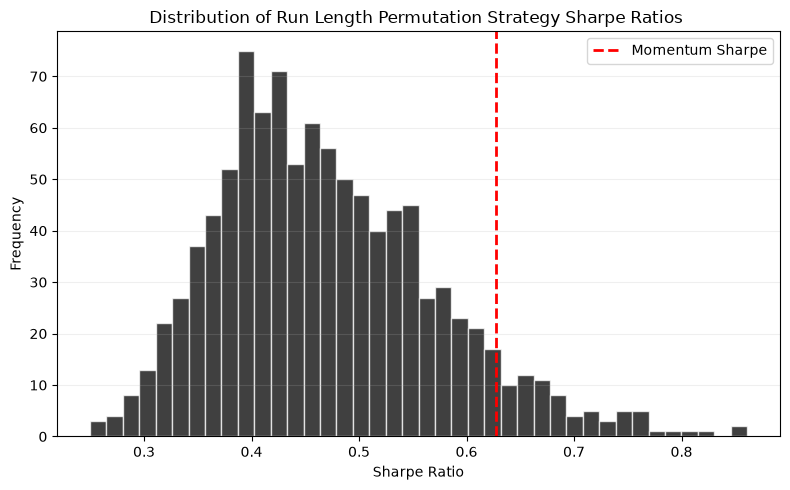

In [20]:
summary(simulation_df, momentum_results, "Distribution of Run Length Permutation Strategy Sharpe Ratios ")